# 02 · Análisis descriptivo y bivariado (OE1)

**Rúbrica G:** métodos de análisis coherentes con los objetivos.

- **Variables continuas:** Shapiro-Wilk en cada grupo. Si ambos grupos son normales se usa media (DE) y t de Welch; si no, mediana [RIC] y U de Mann-Whitney con correlación biserial por rangos como tamaño del efecto.
- **Variables cualitativas:** n (%) y chi cuadrado de Pearson con V de Cramér. Si algún esperado es < 5 se usa la prueba exacta de Fisher (2 × 2) o Monte Carlo.

In [1]:
%run ./00_configuracion.ipynb
df, cc = load_processed()
print(len(df), len(cc))

303 297


In [2]:
def table1(df):
    """Características de la cohorte por diagnóstico, con prueba elegida por supuestos.

    Continuas: Shapiro-Wilk en cada grupo; si ambos p > 0,05 -> media (DE) y t de
    Welch; si no -> mediana [RIC] y U de Mann-Whitney. Categóricas: n (%) y chi
    cuadrado de Pearson, o exacta de Fisher (2x2) / Monte Carlo si algún esperado < 5.
    """
    g0, g1 = df[df.ec == 0], df[df.ec == 1]
    rows = []
    rows.append(dict(variable="n", nivel="", total=f"{len(df)}", sin_ec=f"{len(g0)}",
                     con_ec=f"{len(g1)}", prueba="", p=np.nan, efecto=""))
    for v in CONTINUOUS + DISCRETE:
        a, b = g0[v].dropna(), g1[v].dropna()
        sw0, sw1 = stats.shapiro(a).pvalue, stats.shapiro(b).pvalue
        normal = (sw0 > ALPHA) and (sw1 > ALPHA) and v not in DISCRETE
        if normal:
            f = lambda s: f"{s.mean():.1f} ({s.std():.1f})"
            test, p = "t de Welch", stats.ttest_ind(a, b, equal_var=False).pvalue
            pooled = np.sqrt((a.var() + b.var()) / 2)
            eff = f"d = {(b.mean() - a.mean()) / pooled:.2f}"
        else:
            f = lambda s: f"{s.median():.1f} [{s.quantile(.25):.1f}–{s.quantile(.75):.1f}]"
            res = stats.mannwhitneyu(a, b, alternative="two-sided")
            test, p = "U de Mann-Whitney", res.pvalue
            # correlación biserial por rangos; positiva = valores mayores en Con EC
            r_rb = 1 - 2 * res.statistic / (len(a) * len(b))
            eff = f"r_rb = {r_rb:.2f}"
        meta = VARIABLES[v]
        rows.append(dict(variable=f"{meta['etiqueta']} ({meta['unidad']})", nivel="",
                         total=f(df[v].dropna()), sin_ec=f(a), con_ec=f(b),
                         prueba=test, p=p, efecto=eff,
                         shapiro_p_sin=sw0, shapiro_p_con=sw1))
    for v in BINARY + CATEGORICAL:
        sub = df[[v, "ec"]].dropna()
        ct = pd.crosstab(sub[v], sub["ec"])
        chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
        if (exp < 5).any():
            if ct.shape == (2, 2):
                test, p = "Exacta de Fisher", stats.fisher_exact(ct.values).pvalue
            else:
                res = stats.chi2_contingency(ct, correction=False,
                                             method=stats.MonteCarloMethod(
                                                 n_resamples=20000,
                                                 rng=np.random.default_rng(SEED)))
                test, p = "Chi² (Monte Carlo)", res.pvalue
        else:
            test = "Chi² de Pearson"
        cramer = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
        meta = VARIABLES[v]
        first = True
        for code, lab in meta["categorias"].items():
            if code not in ct.index:
                continue
            n_t = int(ct.loc[code].sum())
            n0, n1 = int(ct.loc[code, 0]), int(ct.loc[code, 1])
            rows.append(dict(
                variable=meta["etiqueta"] if first else "", nivel=lab,
                total=f"{n_t} ({100 * n_t / len(sub):.1f})",
                sin_ec=f"{n0} ({100 * n0 / ct[0].sum():.1f})",
                con_ec=f"{n1} ({100 * n1 / ct[1].sum():.1f})",
                prueba=test if first else "", p=p if first else np.nan,
                efecto=f"V = {cramer:.2f}" if first else ""))
            first = False
    return pd.DataFrame(rows)

## Tabla 1. Características de la cohorte según diagnóstico

In [3]:
t1 = table1(cc)
t1_out = t1.copy(); t1_out["p"] = t1_out.p.map(fmt_p)
for c in ["total", "sin_ec", "con_ec", "efecto"]:  # coma decimal (convención en español)
    t1_out[c] = t1_out[c].str.replace(".", ",", regex=False)
t1_out.to_csv(TABLES / "tabla1_caracteristicas.csv", index=False)
to_latex(t1_out, TABLES / "tabla1_caracteristicas.tex",
         f"Características de la cohorte según diagnóstico angiográfico (n = {len(cc)}). "
         "Continuas: media (DE) o mediana [RIC] según Shapiro-Wilk; cualitativas: n (\\%).",
         "tab:tabla1", ["variable", "nivel", "total", "sin_ec", "con_ec", "prueba", "p", "efecto"],
         ["Variable", "Categoría", "Total", "Sin EC", "Con EC", "Prueba", "p", "Efecto"])
display(t1_out.drop(columns=["shapiro_p_sin", "shapiro_p_con"]))

,variable,nivel,total,sin_ec,con_ec,prueba,p,efecto
0,n,,297,160,137,,,
1,Edad (años),,"56,0 [48,0–61,0]","52,0 [44,8–59,0]","58,0 [53,0–62,0]",U de Mann-Whitney,"< 0,001","r_rb = 0,28"
2,Presión arterial sistólica en reposo (mmHg),,"130,0 [120,0–140,0]","130,0 [120,0–140,0]","130,0 [120,0–145,0]",U de Mann-Whitney,"0,023","r_rb = 0,15"
3,Colesterol sérico total (mg/dL),,"243,0 [211,0–276,0]","235,5 [208,8–268,2]","253,0 [218,0–284,0]",U de Mann-Whitney,"0,047","r_rb = 0,13"
4,Frecuencia cardíaca máxima alcanzada (lpm),,"153,0 [133,0–166,0]","161,0 [149,0–172,0]","142,0 [125,0–157,0]",U de Mann-Whitney,"< 0,001","r_rb = -0,50"
5,Depresión del ST inducida por ejercicio (mm),,"0,8 [0,0–1,6]","0,2 [0,0–1,1]","1,4 [0,6–2,5]",U de Mann-Whitney,"< 0,001","r_rb = 0,47"
6,Vasos mayores coloreados por fluoroscopia (n.º...,,"0,0 [0,0–1,0]","0,0 [0,0–0,0]","1,0 [0,0–2,0]",U de Mann-Whitney,"< 0,001","r_rb = 0,50"
7,Sexo masculino,Mujer,"96 (32,3)","71 (44,4)","25 (18,2)",Chi² de Pearson,"< 0,001","V = 0,28"
8,,Hombre,"201 (67,7)","89 (55,6)","112 (81,8)",,,
9,Glucemia en ayunas > 120 mg/dL,No,"254 (85,5)","137 (85,6)","117 (85,4)",Chi² de Pearson,"0,956","V = 0,00"


### Diagnóstico de normalidad (Shapiro-Wilk por grupo)

In [4]:
display(t1.dropna(subset=['shapiro_p_sin'])[['variable', 'shapiro_p_sin', 'shapiro_p_con', 'prueba']].round(4))

,variable,shapiro_p_sin,shapiro_p_con,prueba
1,Edad (años),0.1110,0.0017,U de Mann-Whitney
2,Presión arterial sistólica en reposo (mmHg),0.0117,0.0002,U de Mann-Whitney
3,Colesterol sérico total (mg/dL),0.0000,0.4319,U de Mann-Whitney
4,Frecuencia cardíaca máxima alcanzada (lpm),0.0010,0.4053,U de Mann-Whitney
5,Depresión del ST inducida por ejercicio (mm),0.0000,0.0000,U de Mann-Whitney
6,Vasos mayores coloreados por fluoroscopia (n.º...,0.0000,0.0000,U de Mann-Whitney


**Interpretación.** Ninguna variable continua es normal en ambos grupos, por lo que todas se comparan con pruebas no
paramétricas. Todas las variables difieren entre grupos (p < 0,05) excepto la glucemia en ayunas. Las mayores diferencias se ven
en el tipo de dolor torácico, la gammagrafía con talio, la angina de esfuerzo, la pendiente del ST, la depresión del ST y el número de vasos.

## Figuras descriptivas

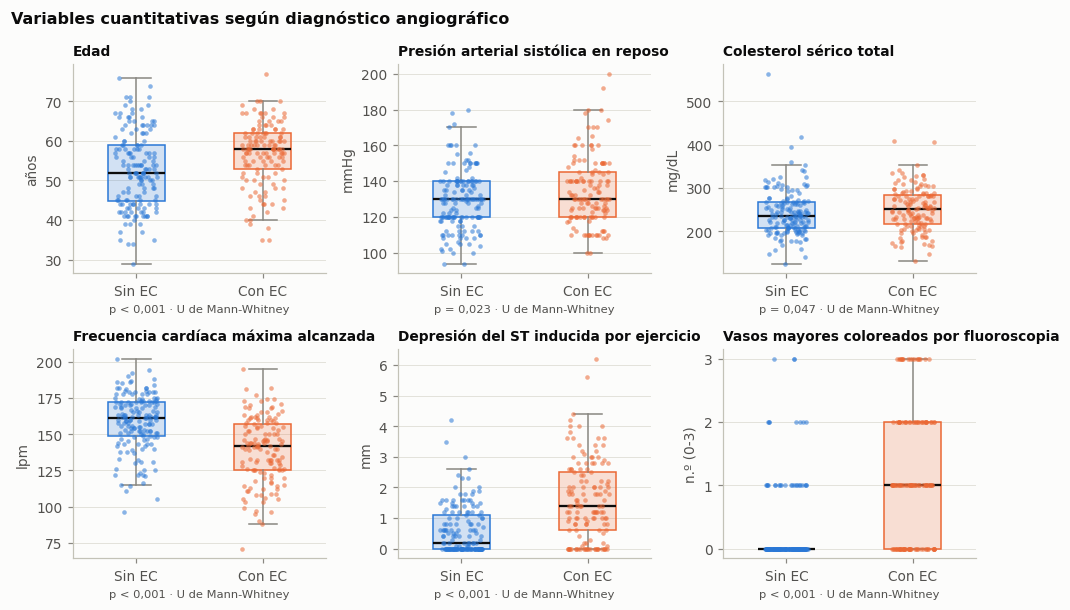

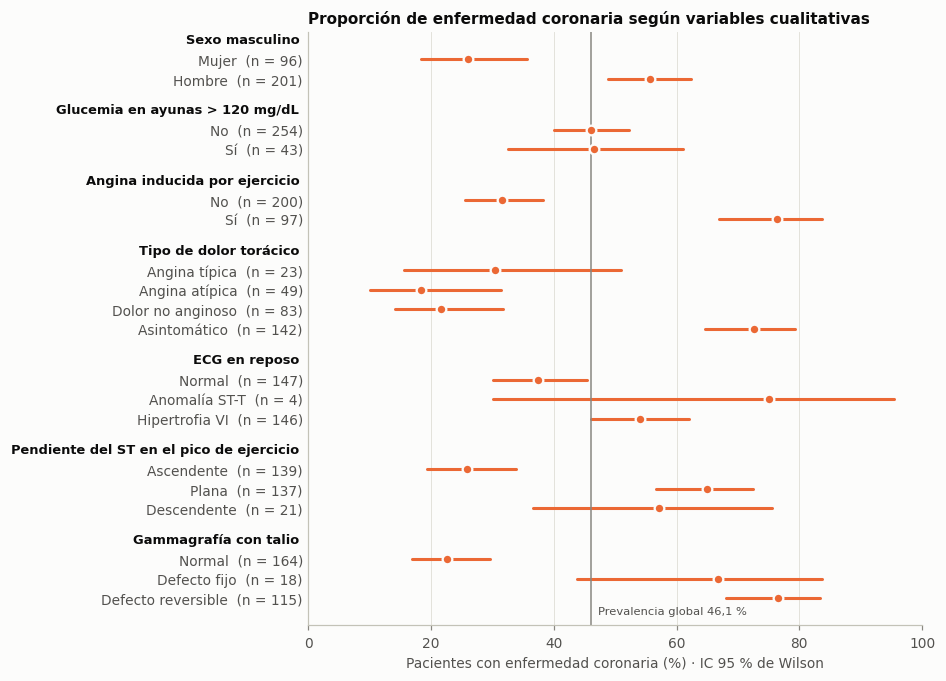

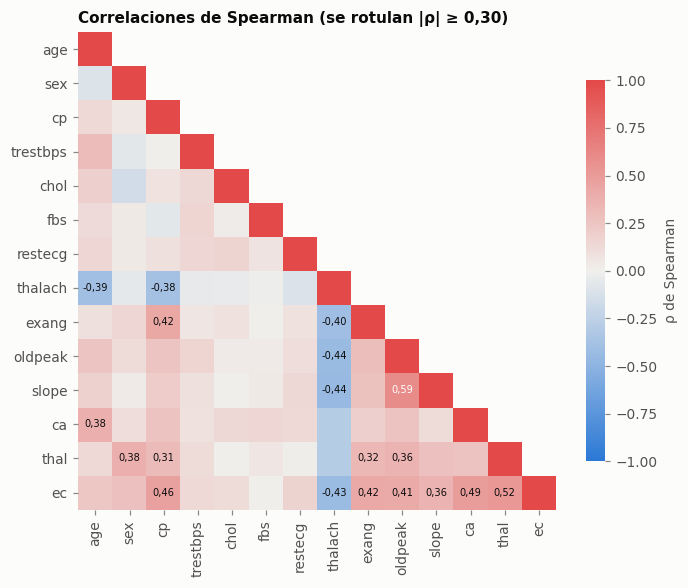

In [5]:
def fig_continuas(df, t1):
    setup(); rng = np.random.default_rng(SEED)
    vars_ = CONTINUOUS + DISCRETE
    fig, axes = plt.subplots(2, 3, figsize=(9, 5.6))
    for ax, v in zip(axes.flat, vars_):
        d = df.dropna(subset=[v])
        _box_strip(ax, [d.loc[d.ec == 0, v], d.loc[d.ec == 1, v]], GROUP_COLORS, GROUP_LABELS, rng)
        meta = VARIABLES[v]
        ax.set_title(meta["etiqueta"], fontsize=9)
        ax.set_ylabel(meta["unidad"])
        row = t1[t1.variable.str.startswith(meta["etiqueta"])].iloc[0]
        ptxt = fmt_p(row.p) if row.p < 0.001 else "= " + fmt_p(row.p)
        ax.set_xlabel(f"p {ptxt} · {row.prueba}", fontsize=7.5)
        if v in DISCRETE:
            ax.set_yticks(range(4))
    fig.suptitle("Variables cuantitativas según diagnóstico angiográfico", x=0.01, ha="left",
                 fontsize=10.5, fontweight="bold")
    fig.tight_layout()
    save(fig, "fig03_continuas_por_diagnostico")


def fig_categoricas(df):
    setup()
    rows = []
    for v in BINARY + CATEGORICAL:
        meta = VARIABLES[v]
        for code, lab in meta["categorias"].items():
            sub = df[df[v] == code]
            if len(sub) == 0:
                continue
            k, n = int(sub.ec.sum()), len(sub)
            lo, hi = wilson(k, n)
            rows.append((meta["etiqueta"], lab, k / n, lo, hi, n))
    r = pd.DataFrame(rows, columns=["var", "nivel", "p", "lo", "hi", "n"])
    fig, ax = plt.subplots(figsize=(7.2, 7))
    y, yt, yl, prev_var = 0, [], [], None
    group_pos = []
    for _, row in r.iterrows():
        if row["var"] != prev_var:
            y -= 0.6; group_pos.append((y, row["var"])); y -= 1; prev_var = row["var"]
        ax.plot([row.lo * 100, row.hi * 100], [y, y], color=K["con_ec"], lw=2, solid_capstyle="round")
        ax.scatter(row.p * 100, y, s=40, color=K["con_ec"], edgecolor=K["surface"], linewidth=1.5, zorder=3)
        yt.append(y); yl.append(f"{row.nivel}  (n = {row.n})"); y -= 1
    prev = df.ec.mean() * 100
    ax.axvline(prev, color=K["muted"], lw=1)
    ax.text(prev + 1, y + 0.6, f"Prevalencia global {prev:.1f} %".replace(".", ","), fontsize=7.5, color=K["ink2"], va="top")
    for gy, gl in group_pos:
        ax.text(-0.015, gy, gl, fontsize=8.5, fontweight="bold", ha="right", va="center",
                transform=ax.get_yaxis_transform())
    ax.set_yticks(yt, yl); ax.set_xlim(0, 100)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Pacientes con enfermedad coronaria (%) · IC 95 % de Wilson")
    ax.set_title("Proporción de enfermedad coronaria según variables cualitativas")
    ax.grid(axis="y", visible=False)
    save(fig, "fig04_categoricas_prevalencia")


def fig_correlacion(df):
    setup()
    cols = UCI_COLUMNS[:-1] + ["ec"]
    corr = df[cols].astype(float).corr(method="spearman")
    cmap = LinearSegmentedColormap.from_list("div", [K["div_neg"], K["div_mid"], K["div_pos"]])
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(7, 6))
    data = np.ma.masked_where(mask, corr.values)
    im = ax.imshow(data, cmap=cmap, vmin=-1, vmax=1)
    for i in range(len(cols)):
        for j in range(i + 1):
            val = corr.values[i, j]
            if i != j and abs(val) >= 0.3:
                ax.text(j, i, f"{val:.2f}".replace(".", ","), ha="center", va="center", fontsize=6.5,
                        color="#ffffff" if abs(val) > 0.55 else K["ink"])
    ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(cols)), cols)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.outline.set_visible(False)
    cb.set_label("ρ de Spearman")
    ax.set_title("Correlaciones de Spearman (se rotulan |ρ| ≥ 0,30)")
    save(fig, "fig05_correlacion_spearman")


fig_continuas(cc, t1)
fig_categoricas(cc)
fig_correlacion(cc)

In [6]:
save_json("02_descriptivo", {"tabla1_p": {r.variable or f"{r.nivel}": r.p for r in t1.itertuples() if not pd.isna(r.p)}})

PosixPath('/home/ana/code/Semestre_4/Healtech_1/Proyecto/results/json/02_descriptivo.json')